# Full example of adaptive setpoint temperature simulation: IBPSA webinar

__Please, note: this Notebook was used as a case study in the [IBPSA Webinar](https://www.youtube.com/watch?v=PQ34Pl7t4HA). However, in that webinar it was adapted to accim version 0.7.1. This Notebook has been updated to suit the latest version of accim.__

In this section, we're going to run a simulation with adaptive setpoint temperatures. Say we want to run some simulations using a [Brazilian local comfort model](https://linkinghub.elsevier.com/retrieve/pii/S0378778817331079) developed by Ricardo Forgiarini Rupp et al [1] in some locations in Brazil, and also we want to **analyse and visualize the data**. First of all, given EnergyPlus 25.1 is installed (the IDF in this folder is for that version), and accim has been installed with its sample files by entering 'pip install "accim[samples]"' in the CMD terminal, let's prepare the files we need: the IDF(s) and the EPW(s). Let's see what file we have in the folder and then we'll continue with the IDF(s).

[1] R.F. Rupp, R. de Dear, E. Ghisi, Field study of mixed-mode office buildings in Southern Brazil using an adaptive thermal comfort framework, Energy and Buildings. 158 (2018) 1475–1486. https://doi.org/10.1016/j.enbuild.2017.11.047.

In [1]:
from os import listdir
input_files = [i for i in listdir()]
print(*input_files, sep='\n')

backup
Current_GC07_Chapeco.epw
Current_GC20_Palmas.epw
full_example_IBPSA.ipynb
RCP852100_GC07_Chapeco.epw
RCP852100_GC20_Palmas.epw
TestModel.idf
__init__.py


The building energy model used is a simple 2-zone model done in DesignBuilder with all parameters by default, for EnergyPlus 25.1 (it is the file `TestModel_onlyGeometryForVRFsystem_2zones_CalcVent_V2510.idf` of the folder `sample IDFs/input_IDFs` of the sample files). To run this notebook, EnergyPlus 25.1 must be installed. We only set the natural ventilation to calculated, and allowed natural ventilation in the HVAC tab for the 2 zones. If you want to have a look at the IDF, you can load it in [Ladybug's Spider IDF Viewer](https://www.ladybug.tools/spider-2020/spider-idf-viewer/v-2020-10-09/spider-idf-viewer.html).

At this point, the methodology is composed of the following sections and subsections:
- __1. Data pre-processing__
    - __1.1. Implementing ACCIS__
    - __1.2. Preparing EPW files__
- __2. Running simulations__
- __3. Data post-processing__
    - __3.1 Visualizing the data__
    - __3.2 Analysing the data__
 
 
 Useful links:
 - Web repository: https://github.com/dsanchez-garcia/accim
 - Documentation: https://accim.readthedocs.io/en/master/
 - Project at Python Package Index: https://pypi.org/project/accim/

## 1. Data pre-processing

### 1.1. Implementing ACCIS (using `AddAccis()`)

Say we have one or multiple IDF files, with an existing HVAC system (in this case, the use of the mixed-mode script type 'ex_mm' is not recommended; only full air-conditioning) or with no HVAC system at all (in this case, any of the script types 'vrf_ac' or 'vrf_mm' are recommended). In this example, we are going to use an IDF without HVAC system, and we are going to use 'vrf_mm' so that accim adds a generic VRF system.

Let's see what IDFs we do have in our folder:

In [2]:
input_idfs = [i for i in listdir() if i.endswith('.idf')]
print(input_idfs)

['TestModel.idf']


First, let's apply 24/7 (always on) schedules to occupancy, so that we have the HVAC system on all the hours of the year. ``set_occupancy_to_always_path`` overwrites the IDF, so we first keep a copy of the original in the folder ``backup``, to restore it at the end of the notebook.

In [3]:
import shutil
from accim.utils import set_occupancy_to_always_path
shutil.copy('TestModel.idf', 'backup/TestModel.idf')
set_occupancy_to_always_path(idfpath='TestModel.idf')

On 24/7 Schedule:Compact object was already in the model.
People Block1:Zone2 Number of People Schedule Name has been set to always occupied.
People Block1:Zone1 Number of People Schedule Name has been set to always occupied.


So now, we're going to generate building energy models with setpoint temperatures based on the Brazilian comfort model (i.e. ``comfort_standard`` takes the value 15). We're going to select the 80% acceptability levels (i.e. ``category`` takes the value 80), and we're going to select the setpoint behaviour to horizontally extend the setpoint temperatures (or comfort limits) when applicability limits are exceeded (i.e. ``comfort_mode`` takes the value 3), and the fully static setpoint temperatures (i.e. ``comfort_mode`` takes the value 0). There are 2 methods to apply adaptive setpoint temperatures:
- Short method, which is running the following two lines of code:
```
from accim.sim import accis
accis.AddAccis()
```

When we run the 2 lines of code above, accim is going to ask us to enter some information it needs to generate the output IDFs. The data we're going to input, in the same order, is:
- Enter the ScriptType: **vrf_mm**
- Enter the SupplyAirTempInputMethod: **temperature difference**
- Do you want to keep the existing outputs (true or false)?: **false**
- Enter the Output type (standard, simplified, detailed or custom): **standard**
- Enter the Output frequencies separated by space (timestep, hourly, daily, monthly, runperiod): **hourly**
- Do you want to generate a dataframe to see all outputs? (true or false): **false**
- Enter the EnergyPlus version (9.1 to 26.2, or auto): **auto** (accim reads the version from the IDF, 25.1)
- Enter the Temperature Control method (temperature or pmv): **temperature**

After that, accim will let us know the information we have entered, and it will start the generic IDF generation process. Lots of actions are going to be performed, and all of them will be printed on screen. Once this process is done, accim will let us know if any of the IDFs is not going to work for any reason, and then it will start the output IDF files generation process. Then, accim will ask us again to enter some information, this time to generate the output IDF(s). The data we are going to enter now is:

- Enter the Comfort Standard numbers separated by space: **15**
- Enter the Category numbers separated by space: **80**
- Enter the Comfort Mode numbers separated by space: **0 3** (where 0 and 3 are respectively static and adaptive setpoints)
- Enter the HVAC Mode numbers separated by space: **1 2** (in this case we have also selected 1 for naturally ventilated, to see the difference with mixed-mode)
- Enter the Ventilation Control numbers separated by space: **0**

For all the remaining arguments, we're going to hit enter to omit it and take the default value. Finally, accim will let us know the list of output IDFs and will ask for confirmation to proceed:

- Do you still want to run ACCIS? [y/n]: **y**

Alternatively, we could specify all the arguments when calling the function, as shown in the cell below. You can find the definition and explanation of the arguments in documentation's [Detailed use section](https://accim.readthedocs.io/en/latest/4_detailed%20use.html#), and the values for the adaptive setpoints in the [full setpoint temperatures table](https://htmlpreview.github.io/?https://github.com/dsanchez-garcia/accim/blob/master/docs/source/html_files/full_setpoint_table.html)

In [4]:
from accim.sim import accis
add_accis_instance = accis.AddAccis(
    script_type='vrf_mm',
    supply_air_temp_input_method='temperature difference',
    keep_existing_outputs=False,
    output_type='standard',
    output_frequencies=['hourly'],
    energyplus_version='auto',
    setpoint_type='temperature',
    comfort_standard=[15],
    category=[80],
    comfort_mode=[0, 3],
    setpoint_accuracy=1000,
    hvac_mode=[1, 2],
    ventilation_control=[0],
    ventilation_setpoint_offset=[0],
    min_outdoor_temp_offset=[50],
    max_wind_speed=[50],
    setpoint_tolerance_step=0.1,
    setpoint_tolerance_start=0.1,
    setpoint_tolerance_end=0.1,
    confirm=True
)


--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v1.0.0
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using AddAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data analysis after simulation
https://accim.readthedocs.io/en/master/jupyter_notebooks/rename_epw_files/using_rename_epw_files.html
-    Using run_ep() to directly run simulations with EnergyPlus
https://accim.readthedocs.io/en/master/jupyter_notebooks/runEp/using_runEp.html
-    Using the class Table() for data analysis
https://accim.readthedocs.io/en/master/jupyter_noteb

VRF Outdoor Unit_Block1:Zone2 Zone List Object has been added
VRF Outdoor Unit_Block1:Zone1 Outdoor Air Node Object has been added
VRF Outdoor Unit_Block1:Zone1 Zone List Object has been added
Block1:Zone2 Sizing:Zone Object has been added
Block1:Zone1 Sizing:Zone Object has been added
Block1:Zone2 Design Specification Outdoor Air Object has been added
Block1:Zone1 Design Specification Outdoor Air Object has been added
Block1:Zone2 Design Specification Zone Air Distribution Object has been added
Block1:Zone1 Design Specification Zone Air Distribution Object has been added
Block1:Zone2 Nodelist Objects has been added
Block1:Zone1 Nodelist Objects has been added
Block1:Zone2 ZoneHVAC:EquipmentConnections Objects has been added
Block1:Zone1 ZoneHVAC:EquipmentConnections Objects has been added
Block1:Zone2 ZoneHVAC:EquipmentList Objects has been added
Block1:Zone1 ZoneHVAC:EquipmentList Objects has been added
Block1:Zone2 ZoneHVAC:TerminalUnit:VariableRefrigerantFlow Object has been added


Added - SetAST_CS13_1 Program
Added - SetAST_CS13_2 Program
Added - SetAST_CS13_3 Program
Added - SetAST_CS14_0 Program
Added - SetAST_CS14_1 Program
Added - SetAST_CS14_2 Program
Added - SetAST_CS14_3 Program
Added - SetAST_CS15_0 Program
Added - SetAST_CS15_1 Program
Added - SetAST_CS16_0 Program
Added - SetAST_CS16_1 Program
Added - SetAST_CS17_0 Program
Added - SetAST_CS17_1 Program
Added - SetAST_CS18_0 Program
Added - SetAST_CS18_1 Program
Added - SetAST_CS19_0 Program
Added - SetAST_CS19_1 Program
Added - SetAST_CS20_0 Program
Added - SetAST_CS20_1 Program
Added - SetAST_CS21_0 Program
Added - SetAST_CS22_0 Program
Added - SetAST_CS99_0 Program
Added - SetAST Program
Added - SetASTnoTol Program
Added - InitASTvariables Program
Added - CountHoursNoApp_Block1_Zone2 Program
Added - SetGeoVarBlock1_Zone2 Program
Added - CountHoursNoApp_Block1_Zone1 Program
Added - SetGeoVarBlock1_Zone1 Program
Added - SetInputData_Block1_Zone2 Program
[... 241 lines not shown in the documentation ..

Ending with file:
TestModel

=======================END OF GENERIC IDF FILE GENERATION PROCESS=======================

The following IDFs will not work, so no output IDFs will be generated from them:
None

=======================START OF OUTPUT IDF FILES GENERATION PROCESS=======================

The list of output IDFs is going to be:
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
And the total number of output IDFs is going to be 4
Generating the following output IDF files:
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_

So, now let's see the list of output IDFs we have generated

In [5]:
output_idfs = [i for i in listdir() if i.endswith('.idf') and i not in input_idfs]
print(*output_idfs, sep='\n')

TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf


Now, let's have a look at the internal variables which have been stored in the ``AddAccis`` instance we have done:

In [6]:
[i for i in dir(add_accis_instance) if not i.startswith('_')]

['arguments',
 'input_idfs',
 'occupied_zones',
 'occupied_zones_original_name',
 'output_idfs',
 'verbose',
 'windows_and_doors',
 'windows_and_doors_original_name',
 'zone_arguments']

For instance, in arguments, you can see the arguments you have previously specified.

In [7]:
add_accis_instance.arguments

{'script_type': 'vrf_mm',
 'supply_air_temp_input_method': 'temperature difference',
 'output_type': 'standard',
 'output_frequencies': ['hourly'],
 'keep_existing_outputs': False,
 'make_outputs_dataframe': False,
 'outputs_dataframe': None,
 'energyplus_version': '25.1',
 'setpoint_type': 'temperature',
 'comfort_standard': [15],
 'category': [80],
 'comfort_mode': [0, 3],
 'hvac_mode': [1, 2],
 'ventilation_control': [0],
 'setpoint_accuracy': 1000,
 'category_cooling_offset': 0,
 'category_heating_offset': 0,
 'custom_cooling_upper_limit': 0,
 'custom_cooling_lower_limit': 0,
 'custom_heating_upper_limit': 0,
 'custom_heating_lower_limit': 0,
 'custom_slope': 0,
 'custom_intercept': 0,
 'custom_cooling_offset': 0,
 'custom_heating_offset': 0,
 'cooling_season_start': 121,
 'cooling_season_end': 274,
 'opening_factor_max_temp_diff': 6,
 'opening_factor_min_temp_diff': 1,
 'min_opening_factor': 0.25,
 'ventilation_setpoint_offset': [0.0],
 'min_outdoor_temp_offset': [50.0],
 'max_win

In variables  ``occupied_zones``, ``occupied_zones_original_name``, ``windows_and_doors`` and
 ``windows_and_doors_original_name`` you can see the zones and windows and doors within the input idfs:

In [8]:
add_accis_instance.occupied_zones

{'TestModel': ['Block1_Zone2', 'Block1_Zone1']}

In [9]:
add_accis_instance.windows_and_doors

{'TestModel': ['Block1_Zone2_Wall_3_0_0_0_0_0_Win',
  'Block1_Zone2_Wall_4_0_0_0_0_0_Win',
  'Block1_Zone2_Wall_5_0_0_0_0_0_Win',
  'Block1_Zone1_Wall_2_0_0_0_0_0_Win',
  'Block1_Zone1_Wall_3_0_0_0_0_0_Win',
  'Block1_Zone1_Wall_5_0_0_0_0_0_Win']}

In variables ``input_idfs`` and ``output_idfs`` you can inspect the input and output idfs using [eppy](https://pypi.org/project/eppy/#description):

In [10]:
add_accis_instance.input_idfs

{'TestModel': <eppy.modeleditor.IDF at 0x22da075fc50>}

In [11]:
add_accis_instance.input_idfs['TestModel'].idfobjects['Schedule:Compact']

[
Schedule:Compact,
    On,                       !- Name
    Any Number,               !- Schedule Type Limits Name
    Through: 12/31,           !- Field 1
    For: AllDays,             !- Field 2
    Until: 24:00,             !- Field 3
    1;                        !- Field 4
, 
Schedule:Compact,
    Off,                      !- Name
    Any Number,               !- Schedule Type Limits Name
    Through: 12/31,           !- Field 1
    For: AllDays,             !- Field 2
    Until: 24:00,             !- Field 3
    0;                        !- Field 4
, 
Schedule:Compact,
    Work efficiency,          !- Name
    Any Number,               !- Schedule Type Limits Name
    Through: 12/31,           !- Field 1
    For: AllDays,             !- Field 2
    Until: 24:00,             !- Field 3
    0;                        !- Field 4
, 
Schedule:Compact,
    OpaqueShade,              !- Name
    Any Number,               !- Schedule Type Limits Name
    Through: 12/31,           !- Fiel

In [12]:
add_accis_instance.input_idfs['TestModel'].idfobjects['EnergyManagementSystem:Program']

[]

Now, let's see the variable ``output_idfs`` 

In [13]:
add_accis_instance.output_idfs

OutputIdfs({'TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf': 'TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf', 'TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf': 'TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf', 'TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf': 'TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf', 'TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf': 'TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf'})

And let's read the first one:

In [14]:
first_model = 'TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf'
programs = add_accis_instance.output_idfs[first_model].idfobjects['EnergyManagementSystem:Program']
print(f'{len(programs)} EMS programs:')
print(*[program.Name for program in programs], sep='\n')

34 EMS programs:
SetComfTemp
CountHours_Block1_Zone2
CountHours_Block1_Zone1
SetAppLimits
ApplyCAT
SetAST_Master
SetAST
SetASTnoTol
InitASTvariables
CountHoursNoApp_Block1_Zone2
SetGeoVarBlock1_Zone2
CountHoursNoApp_Block1_Zone1
SetGeoVarBlock1_Zone1
SetInputData_Block1_Zone2
SetInputData_Block1_Zone1
SetVST
ApplyAST_Block1_Zone2
ApplyAST_Block1_Zone1
SetMyVOF_Block1_Zone2_Wall_3_0_0_0_0_0_Win
SetWindowOperation_Block1_Zone2_Wall_3_0_0_0_0_0_Win
SetMyVOF_Block1_Zone2_Wall_4_0_0_0_0_0_Win
SetWindowOperation_Block1_Zone2_Wall_4_0_0_0_0_0_Win
SetMyVOF_Block1_Zone2_Wall_5_0_0_0_0_0_Win
SetWindowOperation_Block1_Zone2_Wall_5_0_0_0_0_0_Win
SetMyVOF_Block1_Zone1_Wall_2_0_0_0_0_0_Win
SetWindowOperation_Block1_Zone1_Wall_2_0_0_0_0_0_Win
SetMyVOF_Block1_Zone1_Wall_3_0_0_0_0_0_Win
SetWindowOperation_Block1_Zone1_Wall_3_0_0_0_0_0_Win
SetMyVOF_Block1_Zone1_Wall_5_0_0_0_0_0_Win
SetWindowOperation_Block1_Zone1_Wall_5_0_0_0_0_0_Win
RunACCIS_Block1_Zone2
RunACCIS_Block1_Zone1
SetAST_CS15_0
SetAST_CS15_

As you can see, ACCIS is composed of many EMS Program objects: for instance, the programs whose names begin with ``SetAST_CS`` calculate the adaptive setpoint temperatures of the comfort model (an output IDF only has the EMS code of the comfort standards of its zones), and others count the comfort hours or open the windows. Let's see the program ``SetAST``, which runs ``SetAST_Master`` and then applies the setpoint temperatures of the comfort model of this IDF:

In [15]:
[program for program in programs if program.Name == 'SetAST'][0]


ENERGYMANAGEMENTSYSTEM:PROGRAM,
    SetAST,                   !- Name
    run SetAST_Master;        !- Program Line 1

In this case, we have generated more IDFs than we need, so let's remove the others. We only want a single naturally ventilated IDF, to compare the indoor temperature with the mixed-mode IDF with adaptive setpoints. IDFs are NV when ``hvac_mode`` takes the value 1 (``HM_1`` in their names).

In [16]:
idfs_to_be_removed = [i for i in listdir() if i.endswith('.idf') and 'HM_1' in i and 'CS_BRA Rupp NV[CA_80[CM_3[HM_1' not in i]
print(*idfs_to_be_removed, sep='\n')

TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf


In [17]:
from os import remove
for i in idfs_to_be_removed:
    remove(i)

Let's see what IDFs we do finally have:

In [18]:
output_idfs = [i for i in listdir() if i.endswith('.idf') and i not in input_idfs]
print(*output_idfs, sep='\n')


TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf


So, we're done with the IDFs. You can see these have been named based on the input data, separated by the character '['. Let's move to the EPWs.

### 1.2. Preparing EPW files (using `rename_epw_files()`)

Let's see the EPWs we are going to use for the simulations:

In [19]:
original_epws = [i for i in listdir() if i.endswith('.epw')]
print(*original_epws, sep='\n')

Current_GC07_Chapeco.epw
Current_GC20_Palmas.epw
RCP852100_GC07_Chapeco.epw
RCP852100_GC20_Palmas.epw


Now, we're going to rename them. We want them to follow the pattern "Country_City_RCPscenario-Year". But, why is that? Because later, when we run the simulations and read the CSV files, we will be able to analyse them considering the fields Country, City, RCPscenario and Year as categorical variables. So let's rename them running the code in the cell below.

``rename_epw_files`` takes the scenario and the year from the original names ('Current' means the present scenario, and 'RCP852100', the RCP 8.5 scenario in 2100). By default, it takes the city and the country from the coordinates of the EPW files, using OpenStreetMap (see the notebook about ``rename_epw_files``). Here, we give it the city names with ``rename_city_dict`` and their country with ``country_to_city_dict``, so it does not need to look them up.

``rename_epw_files`` will show the new names and ask two questions, which we answer by hitting enter:
- If any of the city or subcountry names needs some amendment (...), please enter the EPW IDs separated by space; otherwise, hit enter to omit: **(hit enter)**
- If you want to exclude some EPWs from renaming, please enter the IDs separated by space, otherwise, hit enter to continue: **(hit enter)**

Since we pass ``confirm_renaming=True``, it will not ask for confirmation, and it will copy the EPW files with the new names. Since we pass ``confirm_deletion=False``, it will keep the original files.

In [20]:
from accim.data.preprocessing import rename_epw_files
rename_epw_files(
    rename_city_dict={
        'Chapeco': 'Chapeco',
        'Palmas': 'Palmas'
    },
    country_to_city_dict={
        'Brazil': ['Chapeco', 'Palmas']
    },
    confirm_renaming=True,
    confirm_deletion=False
)

Since no match has been found between RCP or SSP scenario Year and EPW file name, Present year has been assigned to the following EPW files:
Current_GC07_Chapeco.epw
Current_GC20_Palmas.epw
The geolocation process has taken: 0.08 seconds (0.02 s/EPW)

The previous and new names of the EPW files and their unique IDs are:
ID: 0 / Current_GC07_Chapeco / Brazil_Chapeco_Present
ID: 1 / Current_GC20_Palmas / Brazil_Palmas_Present
ID: 2 / RCP852100_GC07_Chapeco / Brazil_Chapeco_RCP85-2100
ID: 3 / RCP852100_GC20_Palmas / Brazil_Palmas_RCP85-2100

If any of the city or subcountry names needs some amendment (if you are not happy with any of the available options, you can exclude it from renaming at the next stage), please enter the EPW IDs separated by space; otherwise, hit enter to omit:

The final list of previous and new names of the EPW files and their unique IDs is:
ID: 0 / Current_GC07_Chapeco / Brazil_Chapeco_Present
ID: 1 / Current_GC20_Palmas / Brazil_Palmas_Present
ID: 2 / RCP852100_GC

If you cannot use ``rename_epw_files``, you can also copy and rename the files yourself, as long as the new names follow the pattern "Country_City_RCPscenario-Year" (for instance, Brazil_Chapeco_RCP85-2100.epw).

Now, let's see what EPWs we do have:

In [21]:
all_epws = [i for i in listdir() if i.endswith('.epw')]
print(*all_epws, sep='\n')

Brazil_Chapeco_Present.epw
Brazil_Chapeco_RCP85-2100.epw
Brazil_Palmas_Present.epw
Brazil_Palmas_RCP85-2100.epw
Current_GC07_Chapeco.epw
Current_GC20_Palmas.epw
RCP852100_GC07_Chapeco.epw
RCP852100_GC20_Palmas.epw


We can see the new EPWs are:

In [22]:
new_epws = [i for i in listdir() if i.endswith('.epw') if i not in original_epws]
print(*new_epws, sep='\n')

Brazil_Chapeco_Present.epw
Brazil_Chapeco_RCP85-2100.epw
Brazil_Palmas_Present.epw
Brazil_Palmas_RCP85-2100.epw


EPWs are correctly renamed, so now let's move the old EPWs to a different folder to save them as a backup.

In [23]:
import shutil
for i in original_epws:
    shutil.move(i, f'backup/{i}')

Now, we can move to the next stage.

## 2. Running the simulation (using `run_ep()`)

At this point, we have prepared the IDF(s) we are going to simulate, which are

In [24]:
print(*output_idfs, sep='\n')

TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf


as well as the locations where we are going to run those simulations, whose EPWs are:

In [25]:
print(*new_epws, sep='\n')

Brazil_Chapeco_Present.epw
Brazil_Chapeco_RCP85-2100.epw
Brazil_Palmas_Present.epw
Brazil_Palmas_RCP85-2100.epw


So, we are going to simulate all IDF(s) with all EPW(s). When we run later the simulations using accim, the output files (i.e. the CSVs) will be named following the pattern **'idf[epw'**, where the character '[' is used as a separator for later data analysis, so that CSV rows can be grouped by EPW location. You may have noticed the same character is used as a separator in the IDF name, in order to group the CSV rows depending on the input data.

To run the simulations, 2 methods can be used:
- the shorter, in which the following 2 lines of code needs to be run:
    ```
    from accim.run import run
    run.run_ep()
    ```
   After this, you'll be asked to enter the EnergyPlus version (which should coincide with the IDF EnergyPlus version):
    - Please enter the desired EnergyPlus version: **25.1**
    
   Then, you will need to say if you want to run only output IDFs of accim, or otherwise all existing IDFs in the folder:
    - Do you want to run only ACCIM output IDFs? [y or n]: **y**
    
   Next, accim will tell you the IDF(s) and EPW(s) it's going to use for the simulations, and finally all the simulations it's going to run based on the name pattern 'idf[epw'.
   Finally, it will ask for confirmation to proceed with the simulation:
    - Do you still want to proceed? [y or n]:**y**
- the longer method, in which the parameters are specified when calling the function. We'll use the longer method, so let's run the cell below. Since there are a few simulations, it might take a few minutes.

In [26]:
from accim.run import run
run.run_ep(
    only_accim_idfs=True, #only runs output IDFs, that is, IDFs with "[" in its name
    confirm=True, #to skip confirmation
    processes=4, #to specify the number of CPUs to be used
    energyplus_version='25.1', #the EnergyPlus version of the IDFs, which is also the version of EnergyPlus used to run them
)

print('The simulations are done.')

The IDFs we are going to run are:
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
 and the No. of IDFs is going to be 3
The EPWs we are going to run are:
Brazil_Chapeco_Present.epw
Brazil_Chapeco_RCP85-2100.epw
Brazil_Palmas_Present.epw
Brazil_Palmas_RCP85-2100.epw
 and the No. of EPWs is going to be 4
Therefore, the simulations are going to be:
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_RCP85-2100
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_Present
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_RCP85-2100
TestModel[CS_BRA Rupp NV[

So simulations are done. Let's see the CSV files with the results we have now (the files ending in 'Meter.csv', 'Table.csv' and 'Zsz.csv' are other reports of EnergyPlus):

In [27]:
csvs = [i for i in listdir() if i.endswith('.csv') and 'Zsz.csv' not in i and 'Table.csv' not in i and 'Meter.csv' not in i]
print(*csvs, sep='\n')

TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_RCP85-2100.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_Present.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_RCP85-2100.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_RCP85-2100.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_Present.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_RCP85-2100.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.csv
TestModel[CS_BRA Rup

Now, we can move to the last stage, in which data will be analysed and visualized.

## 3. Data post-processing

In order to analyse and visualize the data, we need to make a pandas DataFrame out of the CSVs. We will do this by using the `Table()` class. It will concatenate all the CSVs we specify into a single pandas DataFrame. The class ``Table`` also has some internal variables we can see. These are explained in the [documentation](https://accim.readthedocs.io/en/latest/api/accim.data.postprocessing.html#accim.data.postprocessing.main.Table)

To use this method, a minimum knowledge and experience with Python programming is needed, so if this is not your case, you may struggle to make it work.

In [28]:
from accim.data.postprocessing.main import Table
dataset_hourly = Table(
    #datasets=list
    # This argument expects a list of csv file names.
    # Since we are not specifying any list, it will use all available CSVs in the folder
    # that meet certain conditions in the file name
    
    source_frequency='hourly',
    # This argument tells accim which is the frequency of the input CSVs. 
    # Input CSVs with multiple frequencies are also allowed. 
    # It can be 'timestep', 'hourly', 'daily', 'monthly' and 'runperiod'.
    
    frequency='hourly', 
    # This argument tells accim which is the frequency for the resulting dataframe.
    # If we entered 'daily', accim would aggregate the rows in days.
    # It can be 'hourly', 'daily', 'monthly' and 'runperiod'.
    # For instance, if we entered 'runperiod', since in this case, it's going to concatenate 12 csvs, 
    # the resulting dataframe would have 12 rows;
    # If we entered 'daily', the number of rows would be 365 times 12.
    
    frequency_agg_func='sum', 
    # This argument tells accim the function to be used when the rows are aggregated; can be 'sum' or 'mean'

    idf_path='TestModel.idf',
    # Used to scan the zones from the idf file
    
    standard_outputs=True, 
    # Used to work with a certain selection of output variables
    
    level=['building'], 
    # accim first tries to detect the hierarchy of zones, belonging to blocks, belonging to building.
    # after that, accim will aggregate the output variables into new columns for block and/or building level
    # Therefore, this argument tells accim which level or levels should address, and should be 
    # a list containing the strings 'block' and/or 'building'.
    
    level_agg_func=['sum', 'mean'], 
    # This argument tells accim the functions to be used when the columns are aggregated.
    # It should be a list containing the strings 'sum' and/or 'mean'. 
        
    level_excluded_zones=[],
    # Used to exclude some zone from level computations. 
    # Imagine you want to make the average operative temperature of all zones, 
    # which are air-conditioned, except one which is naturally ventilated.
    # Then you should exclude that zone entering the name here.
    
    split_epw_names=True, 
    # Used to split the categorical variable EPW into multiple columns 
    # for the fields Country, City, RCPscenario and Year
)

Input data frequency in file TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_RCP85-2100.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_Present.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Palmas_RCP85-2100.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.csv is hourly, therefore no aggregation will be performed.
Input data frequency in file TestMod

accim\data\postprocessing\main.py:1213: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Building_Total_' + outputdict[output] + ' (summed)_pymod'] = df[
accim\data\postprocessing\main.py:1216: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Building_Total_' + outputdict[output] + ' (mean)_pymod'] = df[
accim\data\postprocessing\main.py:1213: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once us

As we saw in the documentation, we can access the DataFrame instance and print it:

In [29]:
dataset_hourly.df

,Source,Model,ComfStand,CAT,ComfMod,HVACmode,VentCtrl,VSToffset,MinOToffset,MaxWindSpeed,...,Building_Total_Heating Energy Demand (kWh/m2) (summed),Building_Total_Heating Energy Demand (kWh/m2) (mean),Building_Total_Cooling Energy Consumption (kWh/m2) (summed),Building_Total_Cooling Energy Consumption (kWh/m2) (mean),Building_Total_Heating Energy Consumption (kWh/m2) (summed),Building_Total_Heating Energy Consumption (kWh/m2) (mean),Building_Total_Total Energy Demand (kWh/m2) (summed),Building_Total_Total Energy Demand (kWh/m2) (mean),Building_Total_Total Energy Consumption (kWh/m2) (summed),Building_Total_Total Energy Consumption (kWh/m2) (mean)
0,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.024572,0.012286,0.0,0.0,0.031001,0.007750,0.024572,0.006143
1,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.024809,0.012404,0.0,0.0,0.031057,0.007764,0.024809,0.006202
2,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.026739,0.013370,0.0,0.0,0.033237,0.008309,0.026739,0.006685
3,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.025888,0.012944,0.0,0.0,0.032316,0.008079,0.025888,0.006472
4,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.025453,0.012727,0.0,0.0,0.031851,0.007963,0.025453,0.006363
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105115,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.088430,0.044215,0.0,0.0,0.098401,0.024600,0.088430,0.022107
105116,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.053341,0.026670,0.0,0.0,0.059889,0.014972,0.053341,0.013335
105117,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.041749,0.020874,0.0,0.0,0.048658,0.012164,0.041749,0.010437
105118,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[...,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,0.0,0.0,0.033843,0.016922,0.0,0.0,0.040782,0.010195,0.033843,0.008461


### 3.1 Visualizing the data 

So, we are going to use the ``Table`` instance we just created. Now, let's filter the columns we are going to use, considering we are going to compare indoor temperature with and without adaptive setpoint temperatures:

In [30]:
dataset_hourly.format_table(
    type_of_table='custom', # Used to choose some predefined tables. It can be 'energy demand', 'comfort hours', 'temperature', 'all' or 'custom'
    custom_cols=[ #if type_of_table is 'custom', custom_cols is used to filter the desired columns to keep
        'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
        'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
        'Building_Total_Zone Operative Temperature (°C) (mean)',
        'Block1:Zone2_ASHRAE 55 Running mean outdoor temperature (°C)',
        'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
        'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
        'Building_Total_AFN Zone Infiltration Air Change Rate (ach) (summed)'
    ]
)

Let's print again the DataFrame to see how has changed:

In [31]:
dataset_hourly.df

,Date/time,Model,ComfStand,CAT,ComfMod,HVACmode,VentCtrl,VSToffset,MinOToffset,MaxWindSpeed,...,EPW_Scenario-Year,EPW_Scenario,EPW_Year,Adaptive Cooling Setpoint Temperature_No Tolerance (°C),Adaptive Heating Setpoint Temperature_No Tolerance (°C),Building_Total_Zone Operative Temperature (°C) (mean),Block1:Zone2_ASHRAE 55 Running mean outdoor temperature (°C),Building_Total_Cooling Energy Demand (kWh/m2) (summed),Building_Total_Heating Energy Demand (kWh/m2) (summed),Building_Total_AFN Zone Infiltration Air Change Rate (ach) (summed)
0,01/01 01:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,Present,Present,Present,25.000,20.000,24.885158,23.801389,0.031001,0.0,0.027934
1,01/01 02:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,Present,Present,Present,25.000,20.000,24.896281,23.801389,0.031057,0.0,0.028049
2,01/01 03:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,Present,Present,Present,25.000,20.000,24.900139,23.801389,0.033237,0.0,0.030591
3,01/01 04:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,Present,Present,Present,25.000,20.000,24.895863,23.801389,0.032316,0.0,0.035080
4,01/01 05:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,Present,Present,Present,25.000,20.000,24.895889,23.801389,0.031851,0.0,0.041126
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105115,12/31 20:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,RCP85-2100,RCP85,2100,30.428,22.828,30.263765,34.167454,0.098401,0.0,0.061841
105116,12/31 21:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,RCP85-2100,RCP85,2100,30.428,22.828,30.286825,34.167454,0.059889,0.0,0.081787
105117,12/31 22:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,RCP85-2100,RCP85,2100,30.428,22.828,30.299615,34.167454,0.048658,0.0,0.066560
105118,12/31 23:00:00,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,RCP85-2100,RCP85,2100,30.428,22.828,30.305641,34.167454,0.040782,0.0,0.038477


At this point, you might be confused about what can you analyse and plot. The way to identify the IDFs individually is combining or gathering the categorical variables that make them different. In this case, for the IDFs, these are ComfMod and HVACmode (as we requested in the ``addAccis`` instance). In case of the EPW files, the columns related to these are:

In [32]:
[i for i in dataset_hourly.df if 'EPW' in i]

['EPW',
 'EPW_Country_name',
 'EPW_City_or_subcountry',
 'EPW_Scenario-Year',
 'EPW_Scenario',
 'EPW_Year']

Therefore, ``EPW_City_or_subcountry`` and ``EPW_Scenario-Year`` should be enough to identify them.

To get a clearer view, you can use the method ``gather_vars_query``, which will provide a list of the categorical variables extracted from the csv filename that change, and therefore, can be used in the analysis, and the values these contain. Let's try it:

In [33]:
dataset_hourly.gather_vars_query()

The categorical columns which have different values and those values are:
ComfMod: ['CM_0', 'CM_3']
HVACmode: ['HM_2', 'HM_1']
EPW_City_or_subcountry: ['Chapeco', 'Palmas']
EPW_Scenario-Year: ['Present', 'RCP85-2100']
EPW_Scenario: ['Present', 'RCP85']
EPW_Year: ['Present', '2100']
Month: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
Day: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31']
Hour: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23']


We can see all of the categorical variables are related to the variations in the output idfs and the differences in the epw files. Therefore, we can confirm to cover all the idfs, we would need to use the variables ``ComfMod`` and ``HVACmode``. Also, to cover all epw files, we would need to use the variables ``EPW_City_or_subcountry`` and ``EPW_Scenario-Year``. So, we can enter these variables as a list in the ``gather_vars_query`` method and see what would be the resulting combinations:

In [34]:
dataset_hourly.gather_vars_query(['ComfMod', 'HVACmode'])

The categorical columns which have different values and those values are:
ComfMod: ['CM_0', 'CM_3']
HVACmode: ['HM_2', 'HM_1']
EPW_City_or_subcountry: ['Chapeco', 'Palmas']
EPW_Scenario-Year: ['Present', 'RCP85-2100']
EPW_Scenario: ['Present', 'RCP85']
EPW_Year: ['Present', '2100']
Month: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
Day: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31']
Hour: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23']
The available options resulting from the data entered in vars_to_gather would be: 
CM_0[HM_2
CM_3[HM_1
CM_3[HM_2


In [35]:
dataset_hourly.gather_vars_query(['EPW_City_or_subcountry', 'EPW_Scenario-Year'])

The categorical columns which have different values and those values are:
ComfMod: ['CM_0', 'CM_3']
HVACmode: ['HM_2', 'HM_1']
EPW_City_or_subcountry: ['Chapeco', 'Palmas']
EPW_Scenario-Year: ['Present', 'RCP85-2100']
EPW_Scenario: ['Present', 'RCP85']
EPW_Year: ['Present', '2100']
Month: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
Day: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31']
Hour: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23']
The available options resulting from the data entered in vars_to_gather would be: 
Chapeco[Present
Chapeco[RCP85-2100
Palmas[Present
Palmas[RCP85-2100


Considering the information above, let's plot the figure:

The number of rows and the list of these is going to be:
No. of rows = 4
List of rows:
Chapeco[Present
Chapeco[RCP85-2100
Palmas[Present
Palmas[RCP85-2100
The renamed rows are going to be:
Chapeco Present
Chapeco RCP85-2100
Palmas Present
Palmas RCP85-2100
The number of columns and the list of these is going to be:
No. of columns = 2
List of columns:
CM_3[HM_1
CM_3[HM_2
The renamed columns are going to be:
Brazilian model NV
Brazilian model MM


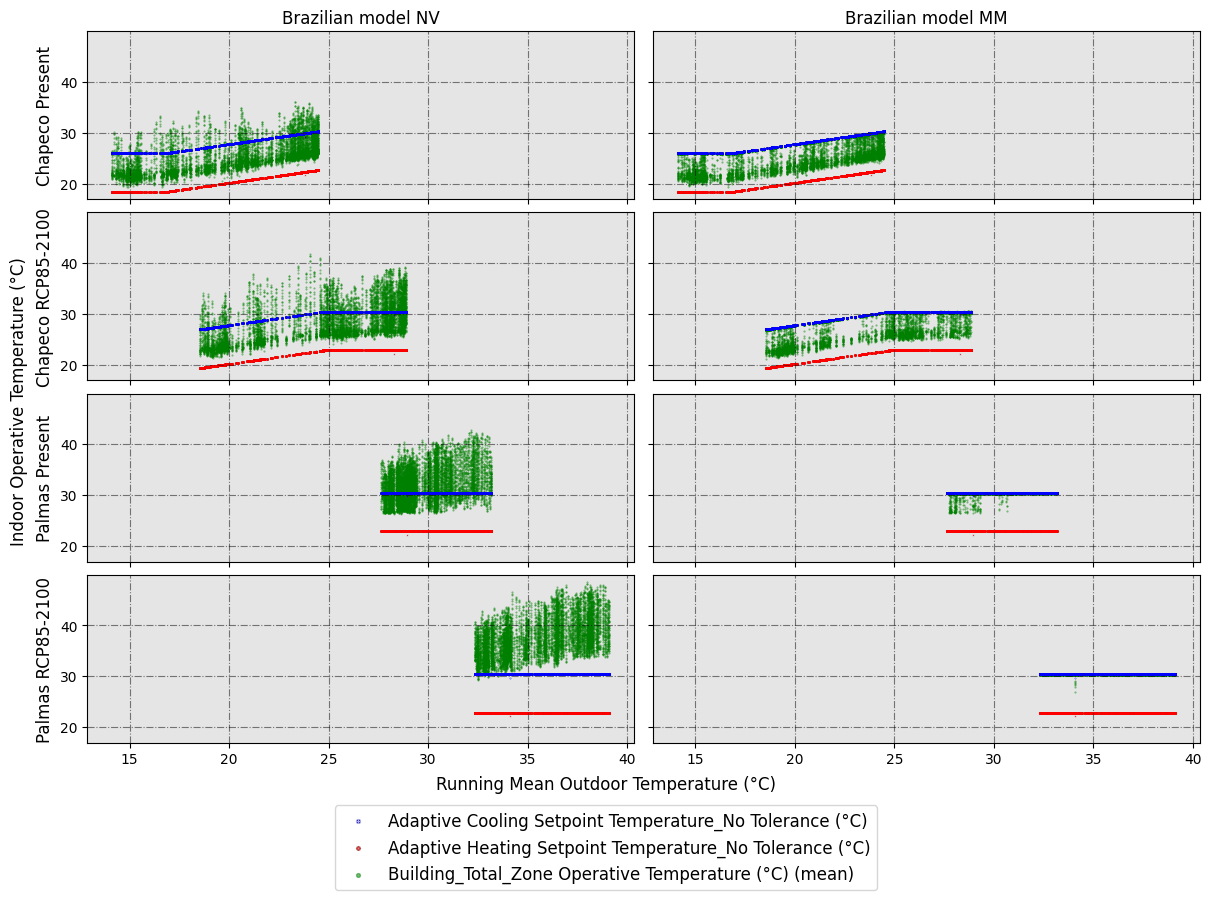

In [36]:
dataset_hourly.scatter_plot(
    vars_to_gather_rows=['EPW_City_or_subcountry', 'EPW_Scenario-Year'], # variables to gather in rows of subplots
    vars_to_gather_cols=['ComfMod', 'HVACmode'],# variables to gather in columns of subplots; all categorical columns which have more than 1 different value across the rows, must be specified in this argument, otherwise you'll get an error.
    detailed_cols=['CM_3[HM_1', 'CM_3[HM_2'], # a list of the specific combinations of arguments to be plotted joined by [
    data_on_x_axis='Block1:Zone2_ASHRAE 55 Running mean outdoor temperature (°C)', #column name (string) for the data on x axis
    data_on_y_main_axis=[ #list which includes the name of the axis on the first place, and then in the second place, a list which includes the column names you want to plot
        [
            'Indoor Operative Temperature (°C)',
            [
                'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
                'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
                'Building_Total_Zone Operative Temperature (°C) (mean)',
            ]
        ],
    ],
    colorlist_y_main_axis=[
        [
            'Indoor Operative Temperature (°C)',
            [
                'b',
                'r',
                'g',
            ]
        ],
    ],
    rows_renaming_dict={
        'Chapeco[Present': 'Chapeco Present',
        'Chapeco[RCP85-2100': 'Chapeco RCP85-2100',
        'Palmas[Present': 'Palmas Present',
        'Palmas[RCP85-2100': 'Palmas RCP85-2100',
    },
    cols_renaming_dict={
        'CM_3[HM_1': 'Brazilian model NV',
        'CM_3[HM_2': 'Brazilian model MM',
    },
    supxlabel='Running Mean Outdoor Temperature (°C)', # data label on x axis
    figname='Scatterplot_NV_vs_MM',
    figsize=6,
    ratio_height_to_width=0.33,
    confirm_graph=True
)

In this figure, you can see on the left column the simulations with free-running (or naturally ventilated) mode, while on the right, the same simulations using mixed-mode with adaptive setpoint temperatures, which introduce all hourly indoor temperatures within the adaptive thermal comfort limits.

Next, let's compare the indoor temperatures of all idfs we have generated, and in this case, we're also going to plot the hourly energy demand on the main y axis, and the air renovation and operative temperature in 2 spines in the twin y axis.

The number of rows and the list of these is going to be:
No. of rows = 4
List of rows:
Chapeco[Present
Chapeco[RCP85-2100
Palmas[Present
Palmas[RCP85-2100
The renamed rows are going to be:
Chapeco Present
Chapeco RCP85-2100
Palmas Present
Palmas RCP85-2100
The number of columns and the list of these is going to be:
No. of columns = 3
List of columns:
CM_3[HM_1
CM_0[HM_2
CM_3[HM_2
The renamed columns are going to be:
Brazilian adaptive NV
Brazilian static MM
Brazilian adaptive MM


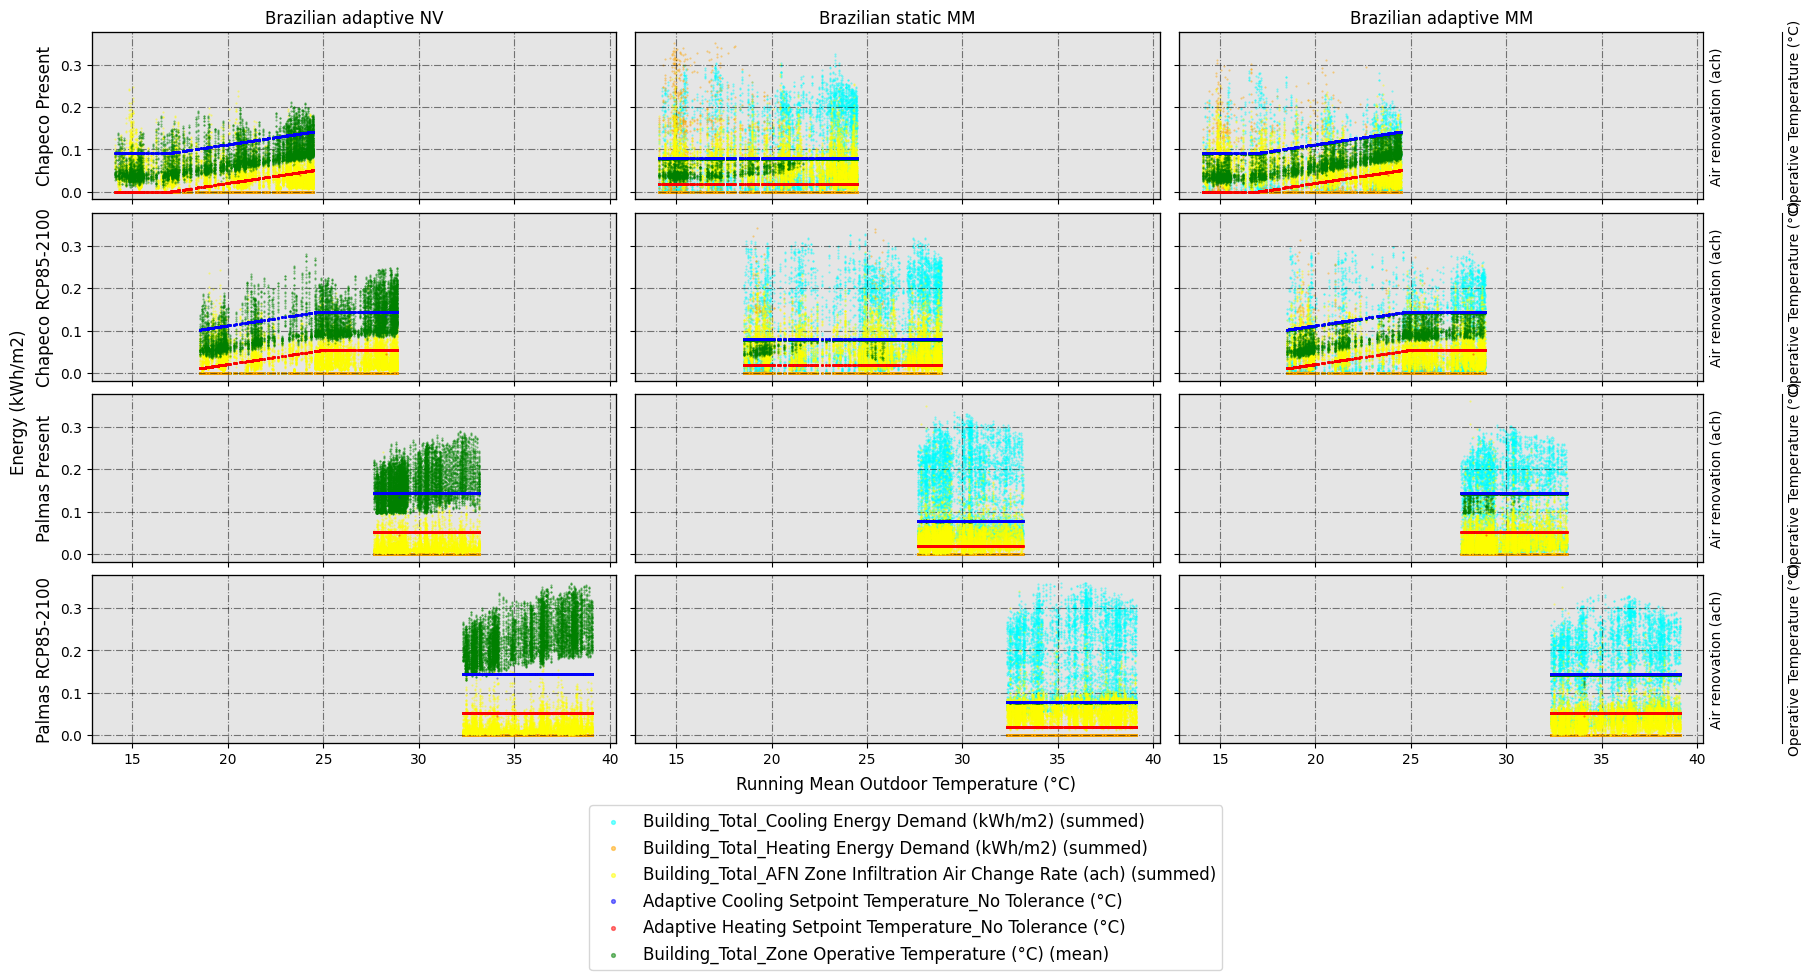

In [37]:
dataset_hourly.scatter_plot(
    vars_to_gather_cols=['ComfMod', 'HVACmode'], # variables to gather in rows of subplots
    vars_to_gather_rows=['EPW_City_or_subcountry', 'EPW_Scenario-Year'],# variables to gather in columns of subplots
    detailed_cols=['CM_0[HM_2', 'CM_3[HM_1', 'CM_3[HM_2'], #we only want to see those combinations
    custom_cols_order=['CM_3[HM_1', 'CM_0[HM_2', 'CM_3[HM_2'],
    data_on_x_axis='Block1:Zone2_ASHRAE 55 Running mean outdoor temperature (°C)', #column name (string) for the data on x axis
    data_on_y_main_axis=[ # similarly to above, a list including the name of the secondary y-axis and the column names you want to plot in it
        [
            'Energy (kWh/m2)',
            [
                'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
                'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
            ]
        ],

    ],
    data_on_y_sec_axis=[ #list which includes the name of the axis on the first place, and then in the second place, a list which includes the column names you want to plot
        [
            'Air renovation (ach)',
            [
                'Building_Total_AFN Zone Infiltration Air Change Rate (ach) (summed)'
            ]
        ],
        [
            'Operative Temperature (°C)',
            [
                'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
                'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
                'Building_Total_Zone Operative Temperature (°C) (mean)',
            ]
        ],
    ],
    colorlist_y_main_axis=[
        [
            'Energy (kWh/m2)',
            [
                'cyan',
                'orange',
            ]
        ],
    ],
    colorlist_y_sec_axis=[
        [
            'Air renovation (ach)',
            [
                'yellow'
            ]
        ],
        [
            'Operative Temperature (°C)',
            [
                'b',
                'r',
                'g',
            ]
        ],
    ],

    rows_renaming_dict={
        'Chapeco[Present': 'Chapeco Present',
        'Chapeco[RCP85-2100': 'Chapeco RCP85-2100',
        'Palmas[Present': 'Palmas Present',
        'Palmas[RCP85-2100': 'Palmas RCP85-2100',
    },
    cols_renaming_dict={
        'CM_3[HM_1': 'Brazilian adaptive NV',        
        'CM_0[HM_2': 'Brazilian static MM',
        'CM_3[HM_2': 'Brazilian adaptive MM',
    },
    supxlabel='Running Mean Outdoor Temperature (°C)', # data label on x axis
    figname=f'scatterplot_BRA_stat_BRA_adap_BRA_nv',
    figsize=6,
    ratio_height_to_width=0.33,
    confirm_graph=True
)

Now, let's plot a similar figure to the first scatterplot, but showing the time in the x axis. In this case, we should use the method ``time_plot``:

The number of rows and the list of these is going to be:
No. of rows = 4
List of rows:
Brazil_Chapeco_Present
Brazil_Chapeco_RCP85-2100
Brazil_Palmas_Present
Brazil_Palmas_RCP85-2100
The renamed rows are going to be:
Chapeco Present
Chapeco RCP85-2100
Palmas Present
Palmas RCP85-2100
The number of columns and the list of these is going to be:
No. of columns = 2
List of columns:
CM_3[HM_1
CM_3[HM_2
The renamed columns are going to be:
Brazilian model NV
Brazilian model MM


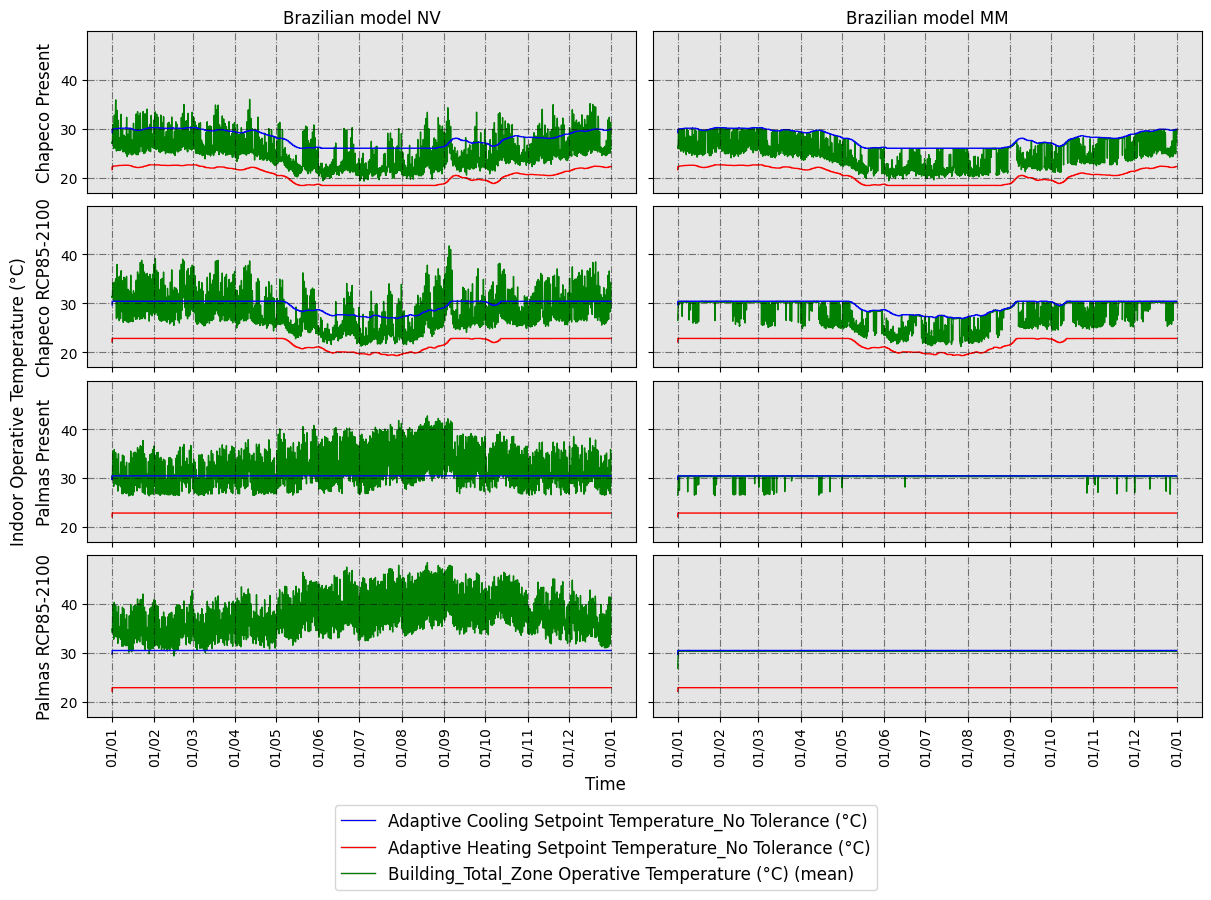

In [38]:
dataset_hourly.time_plot(
    vars_to_gather_rows=['EPW'], # variables to gather in rows of subplots
    vars_to_gather_cols=['ComfMod', 'HVACmode'],# variables to gather in columns of subplots; all categorical columns which have more than 1 different value across the rows, must be specified in this argument, otherwise you'll get an error.
    detailed_cols=['CM_3[HM_1', 'CM_3[HM_2'], # a list of the specific combinations of arguments to be plotted joined by [
    data_on_y_main_axis=[ #list which includes the name of the axis on the first place, and then in the second place, a list which includes the column names you want to plot
        [
            'Indoor Operative Temperature (°C)',
            [
                'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
                'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
                'Building_Total_Zone Operative Temperature (°C) (mean)',
            ]
        ],
    ],
    colorlist_y_main_axis=[
        [
            'Indoor Operative Temperature (°C)',
            [
                'b',
                'r',
                'g',
            ]
        ],
    ],
    rows_renaming_dict={
        'Brazil_Chapeco_Present': 'Chapeco Present',
        'Brazil_Chapeco_RCP85-2100': 'Chapeco RCP85-2100',
        'Brazil_Palmas_Present': 'Palmas Present',
        'Brazil_Palmas_RCP85-2100': 'Palmas RCP85-2100',
    },
    cols_renaming_dict={
        'CM_3[HM_1': 'Brazilian model NV',
        'CM_3[HM_2': 'Brazilian model MM',
    },
    figname='Timeplot_NV_vs_MM',
    figsize=6,
    ratio_height_to_width=0.33,
    confirm_graph=True
)

### 3.2 Analysing the data

Now, let's see how many comfort hours there are, as well as the impact on energy demand. Since we want to see the runperiod totals, we will need to make a new instance of ``Table``, asking for runperiod frequency this time.

In [39]:
from accim.data.postprocessing.main import Table
dataset_runperiod = Table(
    #datasets=list #Since we are not specifying any list, it will use all available CSVs in the folder
    source_frequency='hourly', # This lets accim know which is the frequency of the input CSVs. Input CSVs with multiple frequencies are also allowed. It can be 'hourly', 'daily', 'monthly' and 'runperiod'. It can also be 'timestep' but might generate errors.
    frequency='runperiod', # If 'daily', accim will aggregate the rows in days. It can be 'hourly', 'daily', 'monthly' and 'runperiod'. It can also be 'timestep' but might generate errors.
    frequency_agg_func='sum', #the hourly values of the whole run period are summed
    standard_outputs=True, 
    idf_path='TestModel.idf',
    level=['building'], # A list containing the strings 'block' and/or 'building'. For instance, if ['block', 'building'], accim will generate new columns to sum up or average in blocks and building level.
    level_agg_func=['sum', 'mean'], # A list containing the strings 'sum' and/or 'mean'. For instance, if ['sum', 'mean'], accim will generate the new columns explained in the level argument by summing and averaging.
    level_excluded_zones=[],
    split_epw_names=True, #to split EPW names based on the pattern Country_City_RCPscenario-Year
)

dataset_runperiod.format_table(
    type_of_table='custom',
    custom_cols=[
        'Building_Total_Comfortable Hours_No Applicability (h) (mean)',
        'Building_Total_Total Energy Demand (kWh/m2) (summed)'
    ]
)

No zones have been excluded from level computations.


accim\data\postprocessing\main.py:1213: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Building_Total_' + outputdict[output] + ' (summed)_pymod'] = df[
accim\data\postprocessing\main.py:1216: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Building_Total_' + outputdict[output] + ' (mean)_pymod'] = df[
accim\data\postprocessing\main.py:1213: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once us

Let's see the dataframe we currently have:

In [40]:
dataset_runperiod.df

,Model,ComfStand,CAT,ComfMod,HVACmode,VentCtrl,VSToffset,MinOToffset,MaxWindSpeed,ASTtol,NameSuffix,EPW,Source,EPW_Country_name,EPW_City_or_subcountry,EPW_Scenario-Year,EPW_Scenario,EPW_Year,Building_Total_Comfortable Hours_No Applicability (h) (mean),Building_Total_Total Energy Demand (kWh/m2) (summed)
0,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Chapeco_Present,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,Brazil,Chapeco,Present,Present,Present,8405.916667,850.514764
1,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Chapeco_RCP85-2100,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,Brazil,Chapeco,RCP85-2100,RCP85,2100,8475.333333,962.300547
2,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Palmas_Present,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,Brazil,Palmas,Present,Present,Present,8593.166667,1110.019880
3,TestModel,CS_BRA Rupp NV,CA_80,CM_0,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Palmas_RCP85-2100,TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[...,Brazil,Palmas,RCP85-2100,RCP85,2100,8619.583333,1344.813220
4,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_1,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Chapeco_Present,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[...,Brazil,Chapeco,Present,Present,Present,7353.166667,0.000000
5,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_1,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Chapeco_RCP85-2100,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[...,Brazil,Chapeco,RCP85-2100,RCP85,2100,5884.333333,0.000000
6,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_1,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Palmas_Present,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[...,Brazil,Palmas,Present,Present,Present,3136.916667,0.000000
7,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_1,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Palmas_RCP85-2100,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_1[VC_0[...,Brazil,Palmas,RCP85-2100,RCP85,2100,31.416667,0.000000
8,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Chapeco_Present,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[...,Brazil,Chapeco,Present,Present,Present,8687.083333,314.036825
9,TestModel,CS_BRA Rupp NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,NS_X,Brazil_Chapeco_RCP85-2100,TestModel[CS_BRA Rupp NV[CA_80[CM_3[HM_2[VC_0[...,Brazil,Chapeco,RCP85-2100,RCP85,2100,8634.083333,514.578995


Data is not easy to read like that, so let's make it clearer by using the ``wrangled_table`` method and passing ``multiindex`` in the ``reshaping`` argument:

In [41]:
dataset_runperiod.wrangled_table(reshaping='multiindex')

dataset_runperiod.wrangled_df_multiindex

No reshaping method has been applied, only multiindexing.


Building_Total_Comfortable Hours_No Applicability (h) (mean)  \
ComfMod HVACmode EPW_City_or_subcountry EPW_Scenario EPW_Year                                                                 
CM_0    HM_2     Chapeco                Present      Present                                         8405.916667              
                                        RCP85        2100                                            8475.333333              
                 Palmas                 Present      Present                                         8593.166667              
                                        RCP85        2100                                            8619.583333              
CM_3    HM_1     Chapeco                Present      Present                                         7353.166667              
                                        RCP85        2100                                            5884.333333              
                 Palmas                 Present      Present                                         3136.916667              
                                        RCP85        2100                                              31.416667              
        HM_2     Chapeco                Present      Present                                         8687.083333              
                                        RCP85        2100                                            8634.083333              
                 Palmas                 Present      Present                                         8569.916667              
                                        RCP85        2100                                            8593.666667              

                                                               Building_Total_Total Energy Demand (kWh/m2) (summed)  
ComfMod HVACmode EPW_City_or_subcountry EPW_Scenario EPW_Year                                                        
CM_0    HM_2     Chapeco                Present      Present                                          850.514764     
                                        RCP85        2100                                             962.300547     
                 Palmas                 Present      Present                                         1110.019880     
                                        RCP85        2100                                            1344.813220     
CM_3    HM_1     Chapeco                Present      Present                                            0.000000     
                                        RCP85        2100                                               0.000000     
                 Palmas                 Present      Present                                            0.000000     
                                        RCP85        2100                                               0.000000     
        HM_2     Chapeco                Present      Present                                          314.036825     
                                        RCP85        2100                                             514.578995     
                 Palmas                 Present      Present                                          849.582474     
                                        RCP85        2100                                            1092.014869

Now it's better, but we'd like to unstack the variables ComfMod and HVACmode, that is, move them from rows to columns:

In [42]:
dataset_runperiod.wrangled_table(
    reshaping='unstack',
    vars_to_gather=['ComfMod', 'HVACmode'],
    rename_dict={
        'CM_0[HM_2': 'BRA_Stat_MM',
        'CM_3[HM_1': 'BRA_Adap_NV',
        'CM_3[HM_2': 'BRA_Adap_MM',
    }
)

dataset_runperiod.wrangled_df_unstacked

Building_Total_Comfortable Hours_No Applicability (h) (mean)  \
                                                                                              BRA_Stat_MM   
EPW_City_or_subcountry EPW_Scenario EPW_Year                                                                
Chapeco                Present      Present                                             8405.92             
                       RCP85        2100                                                8475.33             
Palmas                 Present      Present                                             8593.17             
                       RCP85        2100                                                8619.58             

                                                                      \
                                             BRA_Adap_NV BRA_Adap_MM   
EPW_City_or_subcountry EPW_Scenario EPW_Year                           
Chapeco                Present      Present      7353.17     8687.08   
                       RCP85        2100         5884.33     8634.08   
Palmas                 Present      Present      3136.92     8569.92   
                       RCP85        2100           31.42     8593.67   

                                             Building_Total_Total Energy Demand (kWh/m2) (summed)  \
                                                                                      BRA_Stat_MM   
EPW_City_or_subcountry EPW_Scenario EPW_Year                                                        
Chapeco                Present      Present                                              850.51     
                       RCP85        2100                                                 962.30     
Palmas                 Present      Present                                             1110.02     
                       RCP85        2100                                                1344.81     

                                                                      
                                             BRA_Adap_NV BRA_Adap_MM  
EPW_City_or_subcountry EPW_Scenario EPW_Year                          
Chapeco                Present      Present          0.0      314.04  
                       RCP85        2100             0.0      514.58  
Palmas                 Present      Present          0.0      849.58  
                       RCP85        2100             0.0     1092.01

The table above shows us that the comfort hours in NV mode (BRA_Adap_NV) range between 8058.54 and 4399.33 hours, while the same comfort model in mixed-mode with adaptive setpoints (BRA_Adap_MM) ranges between 8723.58 and 8664.96. Since there is no HVAC system in NV mode, the energy demand is 0. With adaptive setpoints, the HVAC energy demand ranges between 314.01 and 1092.01 kWh/m2·year, while with the static setpoints it ranges between 850.88 and 1344.81.

But, what if we want to know the heating, cooling and total energy demand increase or decrease percentage of, for instance, BRA_Adap_MM, compared to the other combinations?

In [43]:
dataset_runperiod.format_table(
    type_of_table='custom',
    custom_cols=[
        'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
        'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
        'Building_Total_Total Energy Demand (kWh/m2) (summed)',
    ]
)

dataset_runperiod.wrangled_table(
    reshaping='unstack',
    vars_to_gather=['ComfMod', 'HVACmode'],
    
    baseline='CM_3[HM_2',
    comparison_mode=['baseline compared to others'],
    comparison_cols=['relative', 'absolute'],
    
    rename_dict={
        'CM_0[HM_2': 'BRA_Stat_MM',
        'CM_3[HM_1': 'BRA_Adap_NV',
        'CM_3[HM_2': 'BRA_Adap_MM',
    },
    transpose=True
)

dataset_runperiod.wrangled_df_unstacked

EPW_City_or_subcountry                                                         Chapeco  \
EPW_Scenario                                                                   Present   
EPW_Year                                                                       Present   
Building_Total_Heating Energy Demand (kWh/m2) (... BRA_Stat_MM                  130.20   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                   80.23   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.38   
                                                   BRA_Stat_MM - BRA_Adap_MM     49.97   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM    -80.23   
Building_Total_Cooling Energy Demand (kWh/m2) (... BRA_Stat_MM                  720.32   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  233.81   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.68   
                                                   BRA_Stat_MM - BRA_Adap_MM    486.51   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM   -233.81   
Building_Total_Total Energy Demand (kWh/m2) (su... BRA_Stat_MM                  850.51   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  314.04   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.63   
                                                   BRA_Stat_MM - BRA_Adap_MM    536.48   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM   -314.04   

EPW_City_or_subcountry                                                                  \
EPW_Scenario                                                                     RCP85   
EPW_Year                                                                          2100   
Building_Total_Heating Energy Demand (kWh/m2) (... BRA_Stat_MM                   26.69   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                   33.10   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)   -0.24   
                                                   BRA_Stat_MM - BRA_Adap_MM     -6.41   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM    -33.10   
Building_Total_Cooling Energy Demand (kWh/m2) (... BRA_Stat_MM                  935.61   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  481.48   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.49   
                                                   BRA_Stat_MM - BRA_Adap_MM    454.13   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM   -481.48   
Building_Total_Total Energy Demand (kWh/m2) (su... BRA_Stat_MM                  962.30   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  514.58   
                                       

For instance, we can see the adaptive setpoints provide reductions in total energy demand compared to the static setpoints ranging between 63 and 19%, depending on the scenarios and climate zones.

Now, we could finally export this table to Excel format for later style edition. Since the reshaping argument we used in the `wrangled_table()` method was 'unstack', the dataframe we are looking for to be exported is `dataset_runperiod.wrangled_df_unstacked`. If we used the 'pivot' argument, the dataframe would have been `dataset_runperiod.wrangled_df_pivoted`. So let's export it:

In [44]:
dataset_runperiod.wrangled_df_unstacked.to_excel('df_unstacked.xlsx')

In [45]:
import pandas as pd

df = pd.read_excel('df_unstacked.xlsx', header=[0, 1, 2], index_col=[0, 1])
df

EPW_City_or_subcountry                                                         Chapeco  \
EPW_Scenario                                                                   Present   
EPW_Year                                                                       Present   
Building_Total_Heating Energy Demand (kWh/m2) (... BRA_Stat_MM                  130.20   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                   80.23   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.38   
                                                   BRA_Stat_MM - BRA_Adap_MM     49.97   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM    -80.23   
Building_Total_Cooling Energy Demand (kWh/m2) (... BRA_Stat_MM                  720.32   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  233.81   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.68   
                                                   BRA_Stat_MM - BRA_Adap_MM    486.51   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM   -233.81   
Building_Total_Total Energy Demand (kWh/m2) (su... BRA_Stat_MM                  850.51   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  314.04   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.63   
                                                   BRA_Stat_MM - BRA_Adap_MM    536.48   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM   -314.04   

EPW_City_or_subcountry                                                                  \
EPW_Scenario                                                                     RCP85   
EPW_Year                                                                          2100   
Building_Total_Heating Energy Demand (kWh/m2) (... BRA_Stat_MM                   26.69   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                   33.10   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)   -0.24   
                                                   BRA_Stat_MM - BRA_Adap_MM     -6.41   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM    -33.10   
Building_Total_Cooling Energy Demand (kWh/m2) (... BRA_Stat_MM                  935.61   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  481.48   
                                                   1-(BRA_Adap_MM/BRA_Stat_MM)    0.49   
                                                   BRA_Stat_MM - BRA_Adap_MM    454.13   
                                                   1-(BRA_Adap_MM/BRA_Adap_NV)    -inf   
                                                   BRA_Adap_NV - BRA_Adap_MM   -481.48   
Building_Total_Total Energy Demand (kWh/m2) (su... BRA_Stat_MM                  962.30   
                                                   BRA_Adap_NV                    0.00   
                                                   BRA_Adap_MM                  514.58   
                                       

Finally, so that we can run this jupyter notebook again, let's leave everything as it was at the beginning.

In [46]:
for i in original_epws:
    shutil.move(f'backup/{i}', i)
shutil.move('backup/TestModel.idf', 'TestModel.idf')

'TestModel.idf'

In [47]:
files_to_delete = [i for i in listdir() if i not in input_files]
print(*files_to_delete, sep='\n')

Brazil_Chapeco_Present.epw
Brazil_Chapeco_RCP85-2100.epw
Brazil_Palmas_Present.epw
Brazil_Palmas_RCP85-2100.epw
df_unstacked.xlsx
scatterplot_BRA_stat_BRA_adap_BRA_nv.png
Scatterplot_NV_vs_MM.png
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.audit
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.bnd
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.csv
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.dxf
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.eio
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[Brazil_Chapeco_Present.end
TestModel[CS_BRA Rupp NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[

In [48]:
for i in files_to_delete:
    remove(i)